In [11]:
# SETUP AND LOAD DATA
from pathlib import Path
import pandas as pd
import numpy as np
import networkx as nx

AIRBNB_DIR = Path("../Airbnb")
CLEANED_FILE = AIRBNB_DIR / "AB_NYC_2019_Cleaned_Final.csv"

if not CLEANED_FILE.exists():
    raise FileNotFoundError(
        f"Cleaned dataset not found: {CLEANED_FILE}"
    )

print("Using cleaned dataset:")
print(CLEANED_FILE)

graph_df = pd.read_csv(CLEANED_FILE)

graph_df.head()

Using cleaned dataset:
../Airbnb/AB_NYC_2019_Cleaned_Final.csv


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6.0,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2.0,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,0.00,1.0,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1.0,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1.0,0


Step 3 — Build the Property Graph

In [12]:
G = nx.Graph()

for _, row in graph_df.iterrows():

    listing_node = f"listing_{row['id']}"
    host_node = f"host_{row['host_id']}"
    neighbourhood_node = f"neighbourhood_{row['neighbourhood']}"
    room_type_node = f"room_type_{row['room_type']}"

    # Add listing node
    G.add_node(
        listing_node,
        node_type="Listing",
        name=row["name"],
        price=row["price"],
        minimum_nights=row["minimum_nights"],
        availability_365=row["availability_365"]
    )

    # Add host node
    G.add_node(
        host_node,
        node_type="Host",
        host_name=row["host_name"]
    )

    # Add neighbourhood node
    G.add_node(
        neighbourhood_node,
        node_type="Neighbourhood",
        neighbourhood_group=row["neighbourhood_group"]
    )

    # Add room type node
    G.add_node(
        room_type_node,
        node_type="Room Type"
    )

    # Add edges
    G.add_edge(host_node, listing_node, relationship="OWNS")
    G.add_edge(listing_node, neighbourhood_node, relationship="LOCATED_IN")
    G.add_edge(listing_node, room_type_node, relationship="HAS_ROOM_TYPE")

Step 4 — Basic Graph Summary

In [13]:
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Graph density:", nx.density(G))

Number of nodes: 81496
Number of edges: 137697
Graph density: 4.146552962274345e-05


Step 5 — Analytics Measure 1: Degree Centrality

In [14]:
degree_centrality = nx.degree_centrality(G)

top_degree = sorted(
    degree_centrality.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

top_degree

[('room_type_Entire home/apt', 0.27951408061844285),
 ('room_type_Private room', 0.2697711516043929),
 ('neighbourhood_Williamsburg', 0.04575740842996503),
 ('neighbourhood_Bedford-Stuyvesant', 0.04457942205043254),
 ('neighbourhood_Harlem', 0.03169519602429597),
 ('neighbourhood_Bushwick', 0.029866862997729924),
 ('neighbourhood_Upper West Side', 0.021939996318792565),
 ("neighbourhood_Hell's Kitchen", 0.02124056690594515),
 ('neighbourhood_East Village', 0.021031965151236273),
 ('neighbourhood_Upper East Side', 0.02049205472728388)]

In [15]:
# Convert to table:
top_degree_df = pd.DataFrame(
    top_degree,
    columns=["Node", "Degree Centrality"]
)

top_degree_df

,Node,Degree Centrality
0,room_type_Entire home/apt,0.279514
1,room_type_Private room,0.269771
2,neighbourhood_Williamsburg,0.045757
3,neighbourhood_Bedford-Stuyvesant,0.044579
4,neighbourhood_Harlem,0.031695
5,neighbourhood_Bushwick,0.029867
6,neighbourhood_Upper West Side,0.021940
7,neighbourhood_Hell's Kitchen,0.021241
8,neighbourhood_East Village,0.021032
9,neighbourhood_Upper East Side,0.020492


Step 6 — Analytics Measure 2: Betweenness Centrality

In [16]:
sample_df = graph_df.sample(1000, random_state=42)

G_sample = nx.Graph()

for _, row in sample_df.iterrows():

    listing_node = f"listing_{row['id']}"
    host_node = f"host_{row['host_id']}"
    neighbourhood_node = f"neighbourhood_{row['neighbourhood']}"
    room_type_node = f"room_type_{row['room_type']}"

    G_sample.add_node(listing_node, node_type="Listing")
    G_sample.add_node(host_node, node_type="Host")
    G_sample.add_node(neighbourhood_node, node_type="Neighbourhood")
    G_sample.add_node(room_type_node, node_type="Room Type")

    G_sample.add_edge(host_node, listing_node, relationship="OWNS")
    G_sample.add_edge(listing_node, neighbourhood_node, relationship="LOCATED_IN")
    G_sample.add_edge(listing_node, room_type_node, relationship="HAS_ROOM_TYPE")

In [17]:
betweenness = nx.betweenness_centrality(G_sample)

top_betweenness = sorted(
    betweenness.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

top_betweenness_df = pd.DataFrame(
    top_betweenness,
    columns=["Node", "Betweenness Centrality"]
)

top_betweenness_df

,Node,Betweenness Centrality
0,room_type_Entire home/apt,0.488193
1,room_type_Private room,0.483494
2,neighbourhood_Williamsburg,0.064072
3,neighbourhood_Bedford-Stuyvesant,0.051744
4,neighbourhood_Bushwick,0.045603
5,neighbourhood_Harlem,0.038064
6,neighbourhood_East Village,0.026037
7,neighbourhood_Hell's Kitchen,0.023677
8,neighbourhood_Upper West Side,0.020853
9,neighbourhood_Midtown,0.018230


Step 7 — Visualise a Small Graph Sample
Do not visualise all 48,895 rows. It will be too messy.

Gephi export completed: airbnb_property_graph_sample.gexf


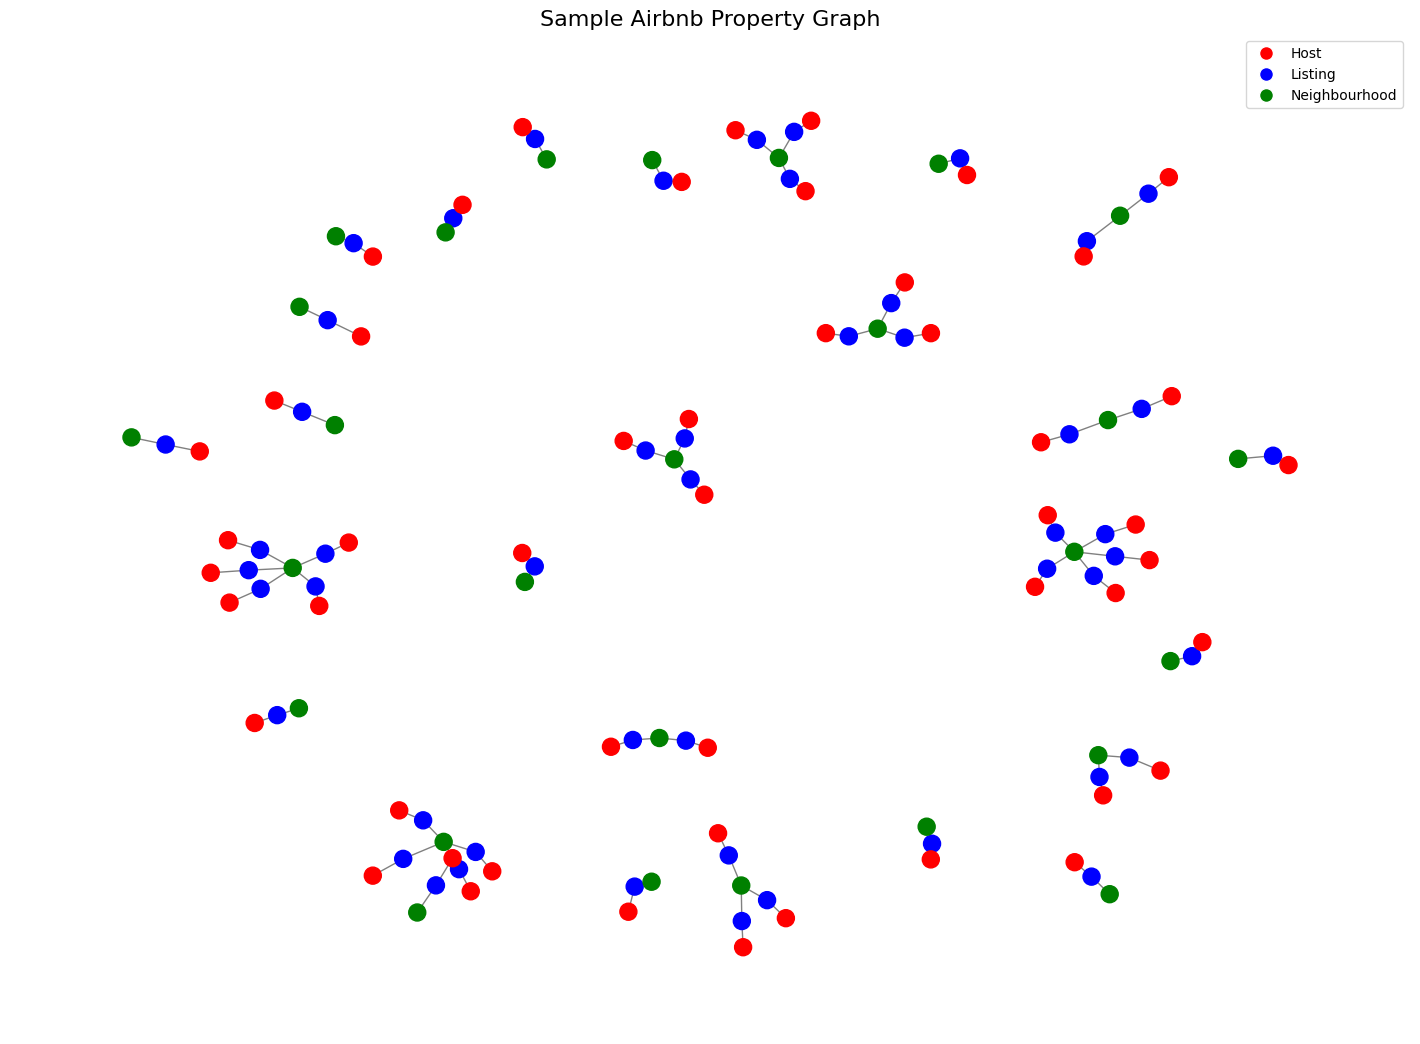

In [18]:
# ------------------------------------------------------------
# VISUALISE SAMPLE AIRBNB PROPERTY GRAPH
# ------------------------------------------------------------

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import networkx as nx

# Create a small sample for visualisation
small_df = graph_df.sample(50, random_state=42)

# Create graph
G_small = nx.Graph()

# Add nodes and edges
for _, row in small_df.iterrows():

    listing_node = f"listing_{row['id']}"
    host_node = f"host_{row['host_id']}"
    neighbourhood_node = f"neighbourhood_{row['neighbourhood']}"

    # Add nodes with node types
    G_small.add_node(listing_node, node_type="Listing")
    G_small.add_node(host_node, node_type="Host")
    G_small.add_node(neighbourhood_node, node_type="Neighbourhood")

    # Add edges
    G_small.add_edge(host_node, listing_node)
    G_small.add_edge(listing_node, neighbourhood_node)

# ------------------------------------------------------------
# GRAPH LAYOUT
# ------------------------------------------------------------

plt.figure(figsize=(14, 10))

# Position nodes
pos = nx.spring_layout(G_small, seed=42)

# ------------------------------------------------------------
# NODE COLORS BASED ON NODE TYPE
# ------------------------------------------------------------

node_colors = []

for node in G_small.nodes(data=True):

    node_type = node[1].get("node_type")

    if node_type == "Host":
        node_colors.append("red")

    elif node_type == "Listing":
        node_colors.append("blue")

    elif node_type == "Neighbourhood":
        node_colors.append("green")

    else:
        node_colors.append("gray")

        # ------------------------------------------------------------
# EXPORT GRAPH FOR GEPHI
# ------------------------------------------------------------

nx.write_gexf(G_small, "airbnb_property_graph_sample.gexf")
nx.write_graphml(G_small, "airbnb_property_graph_sample.graphml")

print("Gephi export completed: airbnb_property_graph_sample.gexf")

# ------------------------------------------------------------
# DRAW GRAPH
# ------------------------------------------------------------

nx.draw(
    G_small,
    pos,
    with_labels=False,
    node_color=node_colors,
    node_size=150,
    edge_color="gray",
    width=1
)

# ------------------------------------------------------------
# ADD LEGEND
# ------------------------------------------------------------

legend_elements = [

    Line2D(
        [0], [0],
        marker='o',
        color='w',
        label='Host',
        markerfacecolor='red',
        markersize=10
    ),

    Line2D(
        [0], [0],
        marker='o',
        color='w',
        label='Listing',
        markerfacecolor='blue',
        markersize=10
    ),

    Line2D(
        [0], [0],
        marker='o',
        color='w',
        label='Neighbourhood',
        markerfacecolor='green',
        markersize=10
    )
]

plt.legend(handles=legend_elements, loc='upper right')

# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

plt.title(
    "Sample Airbnb Property Graph",
    fontsize=16
)

# Remove axes
plt.axis("off")

# Show graph
plt.show()

In [19]:
# Top Hosts by Number of Listings
top_hosts = graph_df.groupby(["host_id", "host_name"]).size().reset_index(name="listing_count")

top_hosts = top_hosts.sort_values(
    by="listing_count",
    ascending=False
).head(10)

top_hosts

,host_id,host_name,listing_count
32885,219517861,Sonder (NYC),272
27961,107434423,Blueground,180
29552,137358866,Kazuya,103
18574,30283594,Kara,95
12119,12243051,Sonder,95
24395,61391963,Corporate Housing,91
13672,16098958,Jeremy & Laura,90
16218,22541573,Ken,87
2904,1475015,Mike,52
9249,7503643,Vida,52


In [20]:
# FULL AIRBNB GRAPH + GEPHI EXPORT
# ------------------------------------------------------------

import pandas as pd
import networkx as nx
from pathlib import Path

# Use the cleaned, non-encoded dataset
df_graph = graph_df.copy()

# Handle basic missing values
df_graph["host_id"] = df_graph["host_id"].fillna("unknown_host")
df_graph["neighbourhood_group"] = df_graph["neighbourhood_group"].fillna("unknown_group")
df_graph["neighbourhood"] = df_graph["neighbourhood"].fillna("unknown_neighbourhood")
df_graph["room_type"] = df_graph["room_type"].fillna("unknown_room_type")

# Create full graph
G = nx.Graph()

for _, row in df_graph.iterrows():

    property_id = f"property_{row['id']}"
    host_id = f"host_{row['host_id']}"
    neighbourhood_group = f"group_{row['neighbourhood_group']}"
    neighbourhood = f"neighbourhood_{row['neighbourhood']}"
    room_type = f"room_type_{row['room_type']}"

    # Property node
    G.add_node(
        property_id,
        node_type="property",
        label=str(row.get("name", "unknown_property")),
        price=float(row["price"]) if pd.notna(row.get("price")) else 0,
        minimum_nights=int(row["minimum_nights"]) if pd.notna(row.get("minimum_nights")) else 0,
        number_of_reviews=int(row["number_of_reviews"]) if pd.notna(row.get("number_of_reviews")) else 0,
        availability_365=int(row["availability_365"]) if pd.notna(row.get("availability_365")) else 0
    )

    # Host node
    G.add_node(
        host_id,
        node_type="host",
        label=str(row.get("host_name", "unknown_host"))
    )

    # Neighbourhood group node
    G.add_node(
        neighbourhood_group,
        node_type="neighbourhood_group",
        label=str(row["neighbourhood_group"])
    )

    # Neighbourhood node
    G.add_node(
        neighbourhood,
        node_type="neighbourhood",
        label=str(row["neighbourhood"])
    )

    # Room type node
    G.add_node(
        room_type,
        node_type="room_type",
        label=str(row["room_type"])
    )

    # Edges
    G.add_edge(property_id, host_id, relationship="listed_by")
    G.add_edge(property_id, neighbourhood, relationship="located_in")
    G.add_edge(neighbourhood, neighbourhood_group, relationship="part_of")
    G.add_edge(property_id, room_type, relationship="has_room_type")

# Check graph size
print("FULL GRAPH CREATED")
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

# Export files
GRAPH_DIR = Path("../graph/gephi_exports")
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

GEXF_FILE = GRAPH_DIR / "airbnb_property_graph_FULL.gexf"
GRAPHML_FILE = GRAPH_DIR / "airbnb_property_graph_FULL.graphml"

nx.write_gexf(G, GEXF_FILE)
nx.write_graphml(G, GRAPHML_FILE)

print("Gephi export completed!")
print("GEXF:", GEXF_FILE)
print("GraphML:", GRAPHML_FILE)

FULL GRAPH CREATED
Nodes: 81501
Edges: 137916
Gephi export completed!
GEXF: ../graph/gephi_exports/airbnb_property_graph_FULL.gexf
GraphML: ../graph/gephi_exports/airbnb_property_graph_FULL.graphml
